In [14]:
import os
import sys

from pymed_paperscraper import PubMed

sys.path.append(os.path.abspath(os.path.join("..")))
from operator import add
from typing import Annotated, TypedDict

import psycopg
from IPython.display import Image, Markdown, display
from langchain_core.messages import SystemMessage
from langgraph.graph import END, START, StateGraph
from langgraph.types import Send
from pydantic import BaseModel, Field

from utils.models import GROQMODELNAMES, ModelName, Models

In [15]:
with psycopg.connect(os.environ["DATABASE_URL"]) as conn, conn.cursor() as curr:
    curr.execute("SELECT version();")
    print(curr.fetchone())

('PostgreSQL 18.7 (a21afb5) on aarch64-unknown-linux-gnu, compiled by gcc (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0, 64-bit',)


In [16]:
models = Models()
llm = models.create_nvidia_model(
    model_name=ModelName.NEMOTRON_3_5_SUPER_VL_120b_a12b.value
)
llm1 = models.create_nvidia_model(model_name=ModelName.NEMOTRON_3_5_BOLT_E4B.value)
llm_groq = models.create_groq_model(model_name=GROQMODELNAMES.GPT_OSS_120B.value)


Creating model nvidia/nemotron-3.5-super-vl-120b-a12b
Creating model nvidia/nemotron-3.5-bolt-e4b
DEBUG:urllib3.connectionpool:Starting new HTTPS connection (1): integrate.api.nvidia.com:443
DEBUG:urllib3.connectionpool:https://integrate.api.nvidia.com:443 "GET /v1/models HTTP/1.1" 200 None


d:\Bluebird\Code 1\Langchain-Foundation\.venv\Lib\site-packages\langchain_nvidia_ai_endpoints\_common.py:269: UserWarning: Found nvidia/nemotron-3.5-bolt-e4b in available_models, but type is unknown and inference may fail.
  warnings.warn(


In [17]:
LLM_ANALYST_INSTRUCTIONS = """You are an expert analyst in the field of topic:{topic}. 
    You are tasked with reviewing a report's/research papers title,abstract,conclusions,results.
    The report is the format each <document doc_id> title abstract conclusions results </document> here is the document\n\n:{document}
    If there is no result in the document, skip the following instructions below and write no result 
    Instructions:
    1. Read the  document i.e.,doc_id,title,abstract,conclusions and results carefully and precisely.In documents with no conclusions and/or results, consider only the title and abstract,treat doc_id as the unique id of every document and state this id in citations, do not invent any number.
    2. Each document has  doc_id,title,abstract,conclusions and results, the title and abstract and conclusions and results if available gives out what the document is about,take this into consideration 
    3. Analyze and review the  document and gather all the necessary and critical details in the data 
    4. Create a report based on all document 
    5. Do not bring outside inferences,assumptions or any information
    6.You report should be based on the document that is available to you and what you analyzed and concluded on the basis of your analysis
    7. After each medical or clinical claim, add the inline citation , using only the doc_id from this document.
    8. The report should be between 100-150 words 
        - One clear Title
        - sub-headers wherever required 
        - citations with doc_id  as inline citation and doc_id and title in the citation sources and these two fields should be as it is in the original document.
    
    The report should based on only on what is included in the data you read.
    """


In [ ]:
RESEARCH_WRITER_INSTRUCTIONS = """
You are a expert research in the field of {topic} and you are reviewing reports from various analysts.
If the analyst reports {analyst_reports} is empty, just write no results and skip the following steps.
Your job in to analyse these analyst reports {analyst_reports} thoroughly  but only on the basis of these reports.

You can analyze, make deductions or conclusions but these only based on what is available in the  analyst reports.
You cannot bring outside information, inferences or any assumptions of your own.
Create combined a single markdown file based on your analysis of all the reports from the analysts.
1. Clear header(title) with #
2. Sub-headers identified with symbol ###
3. Factual analysis based on the analyst reports and adhering to the topic of the reports
4. When you synthesize a claim, you must keep each inline citation attached to the same claim, this applies to all the claims in the every section, including table, synthesis paragraph and conclusions. No exceptions.
5. Add a Sources section at the end. One line per unique paper, paper title plus doc_id, deduplicated.
6. Only cite doc_id and title present in the input, never invent one, and never drop one that was there.
7. The analysis/synthesis  should be one combined report based on all the analyst reports within 500-800 words 
8. There should be a clear and concise conclusion and the conclusion must be clear and concise, and each claim in it must still carry its inline doc_id, same as in the body.
9. The Integrated synthesis must contain the inline citations with doc_id
10. What the final report should not be:
    - Synthesis/analysis of every analyst report separately 
    - Invented or assumptions which cannot be backed by the data in the reports 
"""

 this applies everywhere, including the synthesis table, the synthesis paragraph, and the Conclusion. No section is exempt. And if one sentence covers two 

In [19]:
class OverallState(TypedDict):
    topic: str
    pubmed_results: Annotated[list, add]
    llm_analysis: Annotated[list, add]
    final_report: str
    max_results: int


class PubMedReport(TypedDict):
    """The schema of the report llm expects and the pubmed_search output"""

    topic: str
    document: str


class AnalystReport(BaseModel):
    """Structure for  the Analyst  to Create/Generate a report"""

    title: str = Field(description="Title for analyst's report")
    analysis: str = Field(description="Analysis about the report")


# For Writer to generate structured output
class WriterReport(BaseModel):
    """Structure for the final report"""

    title: str = Field(description="Title of the final report")
    report: str = Field(
        description="One consolidated final report based on all the reports generated by the analyst"
    )


In [20]:
def pubmed_search(state: OverallState):
    query = state["topic"]
    max_results = state["max_results"]
    pubmed = PubMed(tool="langchain", email="jason@aol.com")
    response = pubmed.query(query=query, max_results=max_results)
    results = [a.toDict() for a in response]
    if len(results) >= 0:
        documents = []
        for i in range(len(results)):
            doc = f"<document doc_id={results[i]['pubmed_id']}>title: {results[i]['title']} \n\nabstract: {results[i]['abstract']} \n\n conclusions:{results[i]['conclusions'] or 'none'}</document>"
            documents.append(doc)
        return {"pubmed_results": documents}
    else:
        return {"pubmed_results": "<document>no result</document>"}


In [21]:
def call_llm(state: PubMedReport):
    topic = state["topic"]
    doc = state["document"]
    prompt = LLM_ANALYST_INSTRUCTIONS.format(topic=topic, document=doc)
    response = llm1.with_structured_output(AnalystReport).invoke(
        [SystemMessage(prompt)]
    )
    return {"llm_analysis": [response]}


In [22]:
def should_call_llm(state: OverallState):
    topic = state["topic"]
    if len(state["pubmed_results"]) == 0:
        return "research_writer"
    else:
        return [
            Send("call_llm", {"document": r, "topic": topic})
            for r in state["pubmed_results"]
        ]


In [23]:
def research_writer(state: OverallState):
    topic = state["topic"]
    analysis_report = state["llm_analysis"]
    prompt = RESEARCH_WRITER_INSTRUCTIONS.format(
        topic=topic, analyst_reports=analysis_report
    )
    response = llm_groq.invoke([SystemMessage(prompt)])
    return {"final_report": response}

DEBUG:urllib3.connectionpool:Starting new HTTPS connection (1): mermaid.ink:443
DEBUG:urllib3.connectionpool:https://mermaid.ink:443 "GET /img/LS0tCmNvbmZpZzoKICBmbG93Y2hhcnQ6CiAgICBjdXJ2ZTogbGluZWFyCi0tLQpncmFwaCBURDsKCV9fc3RhcnRfXyhbPHA+X19zdGFydF9fPC9wPl0pOjo6Zmlyc3QKCXB1Ym1lZF9zZWFyY2gocHVibWVkX3NlYXJjaCkKCWNhbGxfbGxtKGNhbGxfbGxtKQoJcmVzZWFyY2hfd3JpdGVyKHJlc2VhcmNoX3dyaXRlcikKCV9fZW5kX18oWzxwPl9fZW5kX188L3A+XSk6OjpsYXN0CglfX3N0YXJ0X18gLS0+IHB1Ym1lZF9zZWFyY2g7CgljYWxsX2xsbSAtLT4gcmVzZWFyY2hfd3JpdGVyOwoJcHVibWVkX3NlYXJjaCAtLi0+IGNhbGxfbGxtOwoJcHVibWVkX3NlYXJjaCAtLi0+IHJlc2VhcmNoX3dyaXRlcjsKCXJlc2VhcmNoX3dyaXRlciAtLT4gX19lbmRfXzsKCWNsYXNzRGVmIGRlZmF1bHQgZmlsbDojZjJmMGZmLGxpbmUtaGVpZ2h0OjEuMgoJY2xhc3NEZWYgZmlyc3QgZmlsbC1vcGFjaXR5OjAKCWNsYXNzRGVmIGxhc3QgZmlsbDojYmZiNmZjCg==?type=png&bgColor=%21white HTTP/1.1" 200 15714


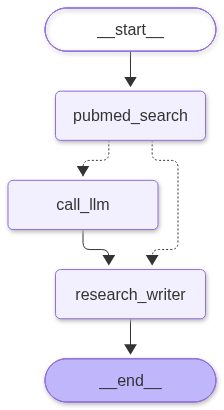

In [24]:
builder = StateGraph(OverallState)
builder.add_node("pubmed_search", pubmed_search)
builder.add_node("call_llm", call_llm)
builder.add_node("research_writer", research_writer)
builder.add_edge(START, "pubmed_search")
builder.add_conditional_edges(
    "pubmed_search", should_call_llm, ["call_llm", "research_writer"]
)
builder.add_edge("call_llm", "research_writer")
builder.add_edge("research_writer", END)
graph = builder.compile()

display(Image(graph.get_graph().draw_mermaid_png()))

In [25]:
response = graph.invoke({"topic": "peptides use in women over 40", "max_results": 3})

DEBUG:urllib3.connectionpool:Starting new HTTPS connection (1): eutils.ncbi.nlm.nih.gov:443
DEBUG:urllib3.connectionpool:https://eutils.ncbi.nlm.nih.gov:443 "GET /entrez/eutils/esearch.fcgi?tool=langchain&email=jason%40aol.com&db=pubmed&term=peptides+use+in+women+over+40&retmax=3&retmode=json HTTP/1.1" 200 None
DEBUG:urllib3.connectionpool:Starting new HTTPS connection (1): eutils.ncbi.nlm.nih.gov:443
DEBUG:urllib3.connectionpool:https://eutils.ncbi.nlm.nih.gov:443 "GET /entrez/eutils/efetch.fcgi?tool=langchain&email=jason%40aol.com&db=pubmed&id=43027328&id=43021180&id=43001810&retmode=xml HTTP/1.1" 200 None


d:\Bluebird\Code 1\Langchain-Foundation\.venv\Lib\site-packages\langchain_nvidia_ai_endpoints\chat_models.py:1397: UserWarning: Model 'nvidia/nemotron-3.5-bolt-e4b' is not known to support structured output. Your output may fail at inference time.
  warnings.warn(


DEBUG:urllib3.connectionpool:Starting new HTTPS connection (1): integrate.api.nvidia.com:443
DEBUG:urllib3.connectionpool:Starting new HTTPS connection (1): integrate.api.nvidia.com:443
DEBUG:urllib3.connectionpool:Starting new HTTPS connection (1): integrate.api.nvidia.com:443


d:\Bluebird\Code 1\Langchain-Foundation\.venv\Lib\site-packages\langchain_nvidia_ai_endpoints\chat_models.py:1397: UserWarning: Model 'nvidia/nemotron-3.5-bolt-e4b' is not known to support structured output. Your output may fail at inference time.
  warnings.warn(


DEBUG:urllib3.connectionpool:https://integrate.api.nvidia.com:443 "POST /v1/chat/completions HTTP/1.1" 200 None
DEBUG:urllib3.connectionpool:https://integrate.api.nvidia.com:443 "POST /v1/chat/completions HTTP/1.1" 200 None
DEBUG:urllib3.connectionpool:https://integrate.api.nvidia.com:443 "POST /v1/chat/completions HTTP/1.1" 200 None
DEBUG:groq._base_client:Request options: {'method': 'post', 'url': '/openai/v1/chat/completions', 'files': None, 'idempotency_key': 'stainless-python-retry-6e54d798-6e70-4c28-82be-77d52a0b805b', 'json_data': {'messages': [{'role': 'system', 'content': 'You are a expert research in the field of peptides use in women over 40 and you are reviewing reports from various analysts.\nIf the analyst reports [AnalystReport(title=\'Cardiovascular Risks in Diabetic Women\', analysis="Premenopausal women without diabetes possess a cardiovascular advantage due to estrogen\'s vasoprotective, anti-inflammatory, and antioxidant effects on the vascular endothelium <document

In [26]:
Markdown(response["final_report"].content)

# Peptide‑Based and Adjunct Therapies for Women ≥ 40 Years: Integrated Evidence Review  

### Cardiovascular Risk Landscape in Diabetic Women  
Premenopausal, non‑diabetic women benefit from estrogen‑mediated vasoprotection, anti‑inflammatory, and antioxidant actions on the endothelium [doc_id=43027328]. In contrast, diabetic women experience a 40–50 % higher relative risk of coronary heart disease and a disproportionate burden of heart failure compared with diabetic men [doc_id=43027328]. The paradoxical pro‑oxidant effect of estradiol in diabetes—via eNOS uncoupling and activation of the AGE‑RAGE axis—drives endothelial dysfunction [doc_id=43027328]. Lifestyle interventions that increase physical activity and skeletal muscle mass can mitigate these risks, with measurable benefits observed specifically in females [doc_id=43027328]. Emerging data suggest that sex‑specific responses to GLP‑1 receptor agonists (GLP‑1RAs) and SGLT2 inhibitors may further refine cardiovascular prevention strategies for diabetic women, but dedicated investigations are still required [doc_id=43027328].

### Weight Management and Metabolic Outcomes with Semaglutide (a GLP‑1RA Peptide)  
In a Korean real‑world cohort, weekly semaglutide 2.4 mg produced a mean body‑weight loss of ‑13.16 % after 12 months [doc_id=43001810]. The effect was amplified in women and younger participants, indicating a potential age‑ and sex‑modulated efficacy [doc_id=43001810]. Beyond weight, semaglutide improved cardiometabolic parameters, liver function tests, and body composition, preferentially reducing adipose tissue while preserving lean mass [doc_id=43001810]. Adverse events were predominantly transient gastrointestinal symptoms, reported in ~22 % of patients, and were generally mild [doc_id=43001810]. Treatment duration averaged 4.9 months with dose escalation to the target 2.4 mg occurring over ~3.5 months, mirroring efficacy observed in the STEP 6 trial despite real‑world variability [doc_id=43001810].

### Implications for Peptide Therapies in Women ≥ 40  
1. **Cardiovascular Considerations** – The heightened cardiovascular vulnerability of diabetic women [doc_id=43027328] underscores the need for peptide agents that confer cardioprotective benefits. GLP‑1RAs, exemplified by semaglutide, have demonstrated weight‑loss and metabolic improvements that could indirectly reduce cardiovascular risk, though direct outcome data in diabetic women ≥ 40 are not yet available in the cited literature.  
2. **Sex‑Specific Pharmacodynamics** – The call for sex‑informed evaluation of GLP‑1RAs and SGLT2 inhibitors [doc_id=43027328] aligns with the observed greater weight‑loss response in women receiving semaglutide [doc_id=43001810], suggesting that peptide efficacy may be enhanced in this demographic.  
3. **Safety Profile** – Gastro‑intestinal adverse events remain the principal limitation of semaglutide, yet their transient nature and low discontinuation rate support its tolerability in women ≥ 40 years [doc_id=43001810].  

### Non‑Peptide Adjuncts: Thermal Ablation for Persistent HPV  
A quasi‑randomized study of 131 Danish women ≥ 40 years with persistent high‑risk HPV infection found that thermal ablation did **not** accelerate viral clearance compared with observation (64.1 % vs. 79.4 % HR‑HPV positivity at 10 months; no significant difference) [doc_id=43021180]. Methylation markers similarly showed no treatment effect, and the intervention failed to provide clinical benefit, necessitating continued surveillance [doc_id=43021180]. While unrelated to peptide therapy, these findings highlight the limited utility of thermal ablation as an adjunctive strategy in this age group.

### Integrated Synthesis  
Women ≥ 40 years, particularly those with diabetes, face amplified cardiovascular risk that is not fully mitigated by lifestyle alone. Peptide‑based GLP‑1RAs such as semaglutide deliver robust weight loss and favorable metabolic shifts, with a safety profile acceptable for long‑term use. The observed sex‑specific efficacy—greater weight reduction in women—supports the hypothesis that peptide therapeutics may confer added advantage in this population, though dedicated cardiovascular outcome trials are needed. Conversely, non‑peptide modalities like thermal ablation do not appear effective for persistent HPV clearance in the same age cohort.

### Conclusion  
- Diabetic women ≥ 40 years have markedly increased cardiovascular risk driven by estrogen‑related oxidative mechanisms, and lifestyle interventions provide measurable but partial benefit [doc_id=43027328].  
- Semaglutide, a GLP‑1RA peptide, achieves significant weight loss (‑13.16 % at 12 months) and metabolic improvements in Korean adults, with enhanced efficacy in women and younger subjects, and a tolerable adverse‑event profile [doc_id=43001810].  
- The lack of efficacy of thermal ablation for HPV clearance in women ≥ 40 years indicates that this non‑peptide approach offers no added clinical advantage [doc_id=43021180].  
Collectively, peptide‑based GLP‑1RA therapy emerges as a promising, sex‑responsive intervention for weight and metabolic management in women over 40, potentially attenuating the heightened cardiovascular risk observed in diabetic cohorts, while alternative thermal modalities do not contribute therapeutic benefit in this demographic.

---

## Sources  
- **Cardiovascular Risks in Diabetic Women** – doc_id=43027328  
- **Effect of thermal ablation on persistent HPV infection in Danish women ≥ 40 years of age: a quasi‑randomized clinical study** – doc_id=43021180  
- **Effectiveness and Safety of Once‑Weekly Semaglutide 2.4 mg in Korean Adults With Obesity or Overweight: A Multicenter Retrospective Real‑World Study (RE‑SEMA‑K Study)** – doc_id=43001810